# Simple prediction models for the cricket-meal broiler trial

## 1. Introduction

The first two notebooks described what happened in the trial. This one asks a different kind of question: can a measurement be predicted before it is taken? There are two tasks.

1. **Forecasting.** How well can the final body weight of a pen (day 35) be forecast from its earlier weekly weights?
2. **Prediction.** How well can the breast meat weight of a bird be predicted from its live weight, sex and diet?

**How much data is there?** According to the dataset description the trial had 624 birds, but the workbook does not hold 624 records. Body weight is stored as one mean per pen per week (24 pens), and single birds only appear where they were sampled (72 birds at day 35 for breast meat). So the models here are fitted to 24 pens or to 72 birds. That decides the approach: few inputs, simple models, a baseline to beat, and a test that never lets a model see the pen it is asked to predict.

## 2. Imports and settings

In [1]:
import hashlib
import platform
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import openpyxl
import pandas as pd
import scipy
import sklearn
from scipy.optimize import curve_fit
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

DATA_FILE = Path("data") / "H Fisher Growth 22 - Open access.xlsx"
FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(exist_ok=True)

## 3. Loading the workbook

The workbook is not stored in this repository (see `data/README.md`). On Colab the next cell asks for it once and saves it under `data/`. The file is only read.

In [2]:
if not DATA_FILE.exists():
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError(f"Download the workbook from Mendeley Data and save it as '{DATA_FILE}'") from None
    uploaded = files.upload()
    DATA_FILE.parent.mkdir(exist_ok=True)
    DATA_FILE.write_bytes(next(iter(uploaded.values())))

print("Workbook:", DATA_FILE.name)
print("SHA-256 :", hashlib.sha256(DATA_FILE.read_bytes()).hexdigest())

sheets_raw = pd.read_excel(DATA_FILE, sheet_name=None, header=None)

Workbook: H Fisher Growth 22 - Open access.xlsx
SHA-256 : 2c0e12849a7441e66ee190f0c438d84d914ceae9d51b9b97367f64ec5737a118


## 4. The two tables

The audit and cleaning of these sheets is in the first two notebooks. Here the two tables that the models need are rebuilt in short form, with checks against the results of those notebooks.

### 4.1 Pen weights by week

Body weights come from the sheet `Growth data`. The first notebook showed three things about this sheet. The weekly records sit in the first columns below the row of labels. The pen column of that table is damaged. The pen number can be restored from treatment and replicate with the 35-day totals table of the same sheet. That table starts in column 27, counted from zero as pandas does (columns AB, AC and AG of the spreadsheet are used).

In [3]:
diet_names = {1: "0% NM", 2: "0% M", 3: "5% CM", 4: "10% CM", 5: "15% CM", 6: "20% CM"}
diet_order = list(diet_names.values())

growth = sheets_raw["Growth data"]
label_row = growth.index[growth[0] == "Pen"][0]
print("Labels of the columns used:", growth.iloc[label_row, [1, 3, 5, 6]].tolist(), "and", growth.iloc[label_row, [27, 28, 32]].tolist())

weekly = growth.iloc[label_row + 1:, [1, 3, 5, 6]].copy()
weekly.columns = ["treatment", "day", "rep", "body_weight_g"]
weekly = weekly.astype({"treatment": int, "day": int, "rep": int, "body_weight_g": float})

pen_key = growth.iloc[label_row + 1:, [27, 28, 32]].dropna()
pen_key.columns = ["pen", "treatment", "rep"]
pen_key = pen_key.astype(int)

weekly = weekly.merge(pen_key, on=["treatment", "rep"], how="left", validate="many_to_one")

# One row per pen, one column per weighing day
pen_weights = weekly.pivot(index="pen", columns="day", values="body_weight_g")
pen_diet = pen_key.set_index("pen")["treatment"].map(diet_names).reindex(pen_weights.index)

print("Pens:", len(pen_weights), "  Weighing days:", pen_weights.columns.tolist(), "  Missing weights:", int(pen_weights.isna().sum().sum()))
print("Pens per diet:", pen_diet.value_counts().reindex(diet_order).to_dict())
print(f"Mean final weight of the 5% CM pens: {pen_weights.loc[pen_diet == '5% CM', 35].mean():.1f} g (first notebook: 1933.4 g)")
pen_weights.round(1).head()

Labels of the columns used: ['Treatment ', 'Day ', 'Rep', 'Average weight (g) '] and ['Pen', 'Treatment ', 'Rep ']
Pens: 24   Weighing days: [0, 7, 14, 21, 28, 35]   Missing weights: 0
Pens per diet: {'0% NM': 4, '0% M': 4, '5% CM': 4, '10% CM': 4, '15% CM': 4, '20% CM': 4}
Mean final weight of the 5% CM pens: 1933.4 g (first notebook: 1933.4 g)


day,0,7,14,21,28,35
pen,,,,,,
1,38.7,138.4,366.6,781.7,1336.6,2067.3
2,38.0,124.1,329.8,729.8,1306.9,2002.4
3,39.7,128.8,353.0,748.6,1347.6,2044.6
4,39.3,152.6,400.0,704.3,1406.4,2098.2
5,39.2,143.1,380.1,702.9,1414.5,2088.8


24 pens with six weighings each and no missing weights. The mean final weight of the 5% CM pens is the value found in the first notebook, so the table has been rebuilt correctly.

### 4.2 Birds at day 35

Breast weights come from the sheet `Meat yield, breast & liver Lab`: the birds sampled on day 35. The second notebook checked this sheet. Breast weight is the sum of the left and the right fillet.

In [4]:
meat_sheet = sheets_raw["Meat yield, breast & liver Lab"]
label_row = meat_sheet.index[meat_sheet[0] == "Pen"][0]
print("Labels of the columns used:", meat_sheet.iloc[label_row, [0, 1, 2, 4, 5, 6, 8]].tolist())

birds = meat_sheet.iloc[label_row + 1:, [0, 1, 2, 4, 5, 6, 8]].copy()
birds.columns = ["pen", "treatment", "bird", "sex", "body_weight_g", "left_breast_g", "right_breast_g"]
birds = birds.astype({"pen": int, "treatment": int, "bird": int,
                      "body_weight_g": float, "left_breast_g": float, "right_breast_g": float}).reset_index(drop=True)

birds["breast_g"] = birds["left_breast_g"] + birds["right_breast_g"]
birds["diet"] = birds["treatment"].map(diet_names)

print("Birds:", len(birds), "  Pens:", birds["pen"].nunique(), "  Birds per pen:", birds.groupby("pen").size().unique().tolist(),
      "  Missing values:", int(birds.isna().sum().sum()))
print("Sexes of the three birds of a pen:", sorted(set(birds.groupby("pen")["sex"].agg(lambda sexes: "".join(sorted(sexes))))))
print("Pen and treatment agree with the growth sheet:", (birds["pen"].map(pen_key.set_index("pen")["treatment"]) == birds["treatment"]).all())
print(f"Mean breast weight: {birds['breast_g'].mean():.1f} g (SD {birds['breast_g'].std():.1f} g)")
birds.head()

Labels of the columns used: ['Pen', 'Treatment', 'Bird ', 'Sex', 'Body weight (g)', 'Left breast weight - Raw (g)', 'Right breast weight - Raw (g)']
Birds: 72   Pens: 24   Birds per pen: [3]   Missing values: 0
Sexes of the three birds of a pen: ['FMM']
Pen and treatment agree with the growth sheet: True
Mean breast weight: 394.7 g (SD 77.8 g)


,pen,treatment,bird,sex,body_weight_g,left_breast_g,right_breast_g,breast_g,diet
0,1,1,1,F,1768.0,169.02,170.25,339.27,0% NM
1,1,1,2,M,2580.0,278.25,262.37,540.62,0% NM
2,1,1,3,M,1860.0,154.37,153.72,308.09,0% NM
3,2,2,1,M,2166.0,190.01,176.18,366.19,0% M
4,2,2,2,F,2014.0,206.80,191.58,398.38,0% M


72 birds, three from each of the 24 pens: one female and two males from every pen.

## 5. How the models are tested

**Leave one pen out.** Each pen is predicted by a model that was fitted to the other 23 pens, and this is repeated for every pen. The errors of these predictions show how a model does on a pen it has not seen. Birds from the same pen share a diet and a pen, so in the second task the three birds of a pen are always left out together.

**A baseline.** The simplest possible prediction is the mean of the other pens. It uses no information about the pen itself. A model is only worth having if it beats that.

**Four numbers** describe the errors:

- **MAE**, the mean absolute error: how far off a prediction is on average, in grams.
- **RMSE**, the root mean squared error: like the MAE, but large errors count more.
- **R2**: the share of the variation that the predictions explain. 1 is perfect, 0 is no better than predicting the overall mean, and below 0 is worse than that.
- **Bias**: the mean of predicted minus observed, in grams. A positive bias means that the predictions are too high on average.

In [5]:
def predict_unseen_pens(model, features, target, pens):
    """Predict every row with a model that was fitted without the pen the row belongs to."""
    return cross_val_predict(model, features, target, groups=pens, cv=LeaveOneGroupOut())


def prediction_errors(observed, predicted):
    """MAE, RMSE and R2 of a set of predictions, plus the bias (mean of predicted minus observed)."""
    error = predicted - observed
    return {
        "MAE (g)": np.abs(error).mean(),
        "RMSE (g)": np.sqrt((error ** 2).mean()),
        "R2": 1 - (error ** 2).sum() / ((observed - observed.mean()) ** 2).sum(),
        "bias (g)": error.mean(),
    }


rounding = {"MAE (g)": 1, "RMSE (g)": 1, "R2": 2, "bias (g)": 1}

## 6. Task A: forecasting the final body weight of a pen

### 6.1 How early can the final weight be forecast?

A straight line is fitted between the weight at one earlier age and the final weight, using 23 pens. The line is then used to forecast the 24th pen.

In [6]:
final_weight = pen_weights[35].to_numpy()
pen_ids = pen_weights.index.to_numpy()
earlier_days = [7, 14, 21, 28]

print(f"Final weight of the 24 pens: mean {final_weight.mean():.0f} g, SD {final_weight.std(ddof=1):.0f} g")

baseline_forecast = predict_unseen_pens(DummyRegressor(strategy="mean"), pen_weights[[28]].to_numpy(), final_weight, pen_ids)

rows = {"mean of the other pens (baseline)": prediction_errors(final_weight, baseline_forecast)}
for day in earlier_days:
    forecast = predict_unseen_pens(LinearRegression(), pen_weights[[day]].to_numpy(), final_weight, pen_ids)
    rows[f"straight line on the weight at day {day}"] = prediction_errors(final_weight, forecast)
forecast_by_age = pd.DataFrame(rows).T
forecast_by_age.round(rounding)

Final weight of the 24 pens: mean 2035 g, SD 73 g


,MAE (g),RMSE (g),R2,bias (g)
mean of the other pens (baseline),62.2,74.6,-0.09,0.0
straight line on the weight at day 7,53.7,69.9,0.04,0.6
straight line on the weight at day 14,45.9,61.0,0.27,1.1
straight line on the weight at day 21,53.1,65.1,0.17,0.6
straight line on the weight at day 28,25.6,30.3,0.82,-0.1


The plain average of the other pens is off by 62 g on average. That is the baseline. It is of the same order as the SD of the final weights (73 g), as it should be for a forecast that knows nothing about the pen.

A forecast from the weight at day 7, 14 or 21 is only a little better (46 to 54 g, R2 of 0.27 at most). The weight at day 28 brings the error down to 26 g and explains 82% of the variation between pens. So the final weight of a pen can be forecast well one week ahead, and only poorly two to four weeks ahead.

One detail is odd: the forecast from day 21 is worse than the one from day 14. The first notebook gives a possible reason.

In [7]:
# First notebook, section 9.1: the listed day-21 weights of pens 4 and 5 fit a pen weight divided by 23 birds,
# the number before the day-20 sampling. Divided by 20 birds, the number that fits their gain column and their
# day-28 weight, the same pen weights give the likelier values.
likelier_day21 = pen_weights[21].copy()
likelier_day21.loc[[4, 5]] = likelier_day21.loc[[4, 5]] * 23 / 20
print("Day-21 weights of pens 4 and 5 (g): listed", pen_weights.loc[[4, 5], 21].round().astype(int).tolist(),
      " likelier", likelier_day21.loc[[4, 5]].round().astype(int).tolist())

forecast = predict_unseen_pens(LinearRegression(), likelier_day21.to_numpy().reshape(-1, 1), final_weight, pen_ids)
print(f"MAE of the day-21 forecast: {forecast_by_age.loc['straight line on the weight at day 21', 'MAE (g)']:.1f} g with the listed weights, "
      f"{prediction_errors(final_weight, forecast)['MAE (g)']:.1f} g with the likelier weights of pens 4 and 5")

Day-21 weights of pens 4 and 5 (g): listed [704, 703]  likelier [810, 808]
MAE of the day-21 forecast: 53.1 g with the listed weights, 44.8 g with the likelier weights of pens 4 and 5


With the likelier day-21 weights of these two pens the oddity is gone. The error falls from 53 to 45 g, about the same as for the forecast from day 14. A data problem that the audit found in the first notebook shows up again here as a model problem.

### 6.2 Other ways to forecast

Five other approaches, from very simple to more flexible:

- **Last week's gain repeats.** The pen gains as much from day 28 to day 35 as it did from day 21 to day 28.
- **Growth curve.** A Gompertz curve, a standard S-shaped growth model, is fitted to the five weights of a pen up to day 28 and extended to day 35. This uses only the pen's own data.
- **Straight line on all four earlier weights** (days 7, 14, 21 and 28) instead of the day-28 weight alone.
- **Nearest neighbours.** The forecast is the mean final weight of the five pens whose earlier weights were most similar.
- **Random forest.** The average of 500 decision trees, a common flexible model.

In [8]:
def gompertz(age, mature_weight, b, k):
    """Gompertz growth curve: weight at a given age."""
    return mature_weight * np.exp(-b * np.exp(-k * age))


def gompertz_forecast(weights, days=(0, 7, 14, 21, 28), target_day=35):
    """Fit a Gompertz curve to the weights of one pen and read off the weight at the target day."""
    parameters, _ = curve_fit(gompertz, days, weights, p0=[5000, 4.8, 0.04], maxfev=20000)
    return gompertz(target_day, *parameters)


weights_to_day28 = pen_weights[earlier_days].to_numpy()

forecasts = {
    "mean of the other pens (baseline)": baseline_forecast,
    "last week's gain repeats": (pen_weights[28] + (pen_weights[28] - pen_weights[21])).to_numpy(),
    "growth curve fitted to each pen (Gompertz)":
        np.array([gompertz_forecast(pen_weights.loc[pen, [0, 7, 14, 21, 28]].to_numpy()) for pen in pen_ids]),
    "straight line on the weight at day 28":
        predict_unseen_pens(LinearRegression(), pen_weights[[28]].to_numpy(), final_weight, pen_ids),
    "straight line on the weights at days 7 to 28":
        predict_unseen_pens(LinearRegression(), weights_to_day28, final_weight, pen_ids),
    "nearest neighbours on the weights at days 7 to 28":
        predict_unseen_pens(make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5)), weights_to_day28, final_weight, pen_ids),
    "random forest on the weights at days 7 to 28":
        predict_unseen_pens(RandomForestRegressor(n_estimators=500, random_state=0), weights_to_day28, final_weight, pen_ids),
}
forecast_results = pd.DataFrame({name: prediction_errors(final_weight, forecast) for name, forecast in forecasts.items()}).T
forecast_results.round(rounding)

,MAE (g),RMSE (g),R2,bias (g)
mean of the other pens (baseline),62.2,74.6,-0.09,0.0
last week's gain repeats,103.8,109.9,-1.37,-99.8
growth curve fitted to each pen (Gompertz),102.6,153.9,-3.64,59.8
straight line on the weight at day 28,25.6,30.3,0.82,-0.1
straight line on the weights at days 7 to 28,21.2,25.4,0.87,-0.2
nearest neighbours on the weights at days 7 to 28,35.3,42.5,0.65,-4.8
random forest on the weights at days 7 to 28,33.1,39.2,0.70,0.3


In [9]:
curve_error = pd.Series(forecasts["growth curve fitted to each pen (Gompertz)"] - final_weight, index=pen_ids)
print("Growth curve, the three largest errors (pen: g):", curve_error.abs().nlargest(3).round(0).astype(int).to_dict())

day28_line = LinearRegression().fit(pen_weights[[28]].to_numpy(), final_weight)
print(f"Straight line fitted to all 24 pens: final weight = {day28_line.intercept_:.0f} g + {day28_line.coef_[0]:.2f} x weight at day 28")
print(f"MAE of the day-28 forecast as a share of the mean final weight: {100 * forecast_results.loc['straight line on the weight at day 28', 'MAE (g)'] / final_weight.mean():.1f}%")

Growth curve, the three largest errors (pen: g): {5: 469, 4: 408, 9: 276}
Straight line fitted to all 24 pens: final weight = 494 g + 1.14 x weight at day 28
MAE of the day-28 forecast as a share of the mean final weight: 1.3%


- **The two methods that use only the pen's own history are worse than the baseline**, with errors of 104 and 103 g. Repeating the last gain is too low by 100 g on average, because the pens gained more in the last week than in the week before. The growth curve is too high by 60 g on average. A curve fitted to five points bends with every wobble in them, and the error grows when the curve is extended beyond the data. Its two largest errors (469 and 408 g) are for pens 5 and 4, the two pens with the doubtful day-21 weight.
- **The straight-line models are the best** (21 and 26 g). The day-28 model is off by 1.3% of the final weight on average. These models do not extend a curve. They learn from the other pens how the weight at day 28 relates to the final weight: about 494 g plus 1.14 times the weight at day 28.
- **Nearest neighbours and random forest** beat the baseline (35 and 33 g) but not the straight line. With 23 pens to learn from, a flexible model has too little to work with.

Using all four earlier weights instead of the day-28 weight alone lowers the error from 26 to 21 g. With 24 pens, a difference of that size is not enough to prefer one of the two.

## 7. Task B: predicting the breast weight of a bird

### 7.1 Models

The target is the breast weight of a bird (both fillets, in g). The inputs are things that are known without cutting the bird up: live weight, sex and diet. Sex is coded as 1 for males and 0 for females. Diet enters as five yes/no columns, one for each diet other than the non-medicated control.

The same kinds of model are compared as in Task A: a baseline, straight lines and a random forest. Nearest neighbours is left out here. For several birds, two other birds are exactly equally similar. The method then has to pick one of them arbitrarily, and its result depends on that pick.

In [10]:
birds["male"] = (birds["sex"] == "M").astype(int)
diet_columns = []
for diet in diet_order[1:]:
    birds[f"diet {diet}"] = (birds["diet"] == diet).astype(int)
    diet_columns.append(f"diet {diet}")

breast_weight = birds["breast_g"].to_numpy()
bird_pens = birds["pen"].to_numpy()

weight_only = ["body_weight_g"]
weight_sex = ["body_weight_g", "male"]
weight_sex_diet = ["body_weight_g", "male"] + diet_columns

candidates = {
    "mean of the other pens (baseline)": (DummyRegressor(strategy="mean"), weight_only),
    "straight line: live weight": (LinearRegression(), weight_only),
    "straight line: live weight + sex": (LinearRegression(), weight_sex),
    "straight line: live weight + sex + diet": (LinearRegression(), weight_sex_diet),
    "random forest: live weight + sex": (RandomForestRegressor(n_estimators=500, random_state=0), weight_sex),
    "random forest: live weight + sex + diet": (RandomForestRegressor(n_estimators=500, random_state=0), weight_sex_diet),
}

breast_predictions = {
    name: predict_unseen_pens(model, birds[columns].to_numpy(dtype=float), breast_weight, bird_pens)
    for name, (model, columns) in candidates.items()
}
breast_results = pd.DataFrame({name: prediction_errors(breast_weight, predicted) for name, predicted in breast_predictions.items()}).T
breast_results.round(rounding)

,MAE (g),RMSE (g),R2,bias (g)
mean of the other pens (baseline),60.5,78.5,-0.03,0.0
straight line: live weight,34.4,41.2,0.72,-0.2
straight line: live weight + sex,27.3,33.8,0.81,-0.1
straight line: live weight + sex + diet,26.5,33.9,0.81,0.0
random forest: live weight + sex,34.6,41.9,0.71,-1.8
random forest: live weight + sex + diet,33.3,41.7,0.71,-1.8


- The baseline is off by 60.5 g on average (the breast weights have an SD of 78 g).
- Live weight alone brings the error down to 34.4 g.
- Adding sex brings it to 27.3 g. The predictions then explain 81% of the variation between birds.
- Adding diet makes no real difference (26.5 g, the same R2).
- The random forest (34.6 and 33.3 g) does about as well as the straight line on live weight alone, and clearly worse than the straight line with sex.

The two straight-line models with sex are equally good. I keep the simpler one, with live weight and sex.

### 7.2 What the chosen model says, and why the flexible model does worse

In [11]:
features = birds[weight_sex].to_numpy(dtype=float)

line = LinearRegression().fit(features, breast_weight)
print("Fitted to all 72 birds (weights in g, male = 1 for a male and 0 for a female):")
print(f"  breast weight = {line.intercept_:.1f} + {line.coef_[0]:.3f} x live weight {'-' if line.coef_[1] < 0 else '+'} {abs(line.coef_[1]):.1f} x male")

chosen = "straight line: live weight + sex"
relative_error = np.abs(breast_predictions[chosen] - breast_weight) / breast_weight
print(f"Error of this model on birds from an unseen pen: {100 * relative_error.mean():.1f}% of the breast weight on average, "
      f"largest error {np.abs(breast_predictions[chosen] - breast_weight).max():.0f} g")
print()

# The same two models, judged on the birds they were fitted to and on birds from a pen they had not seen
forest = RandomForestRegressor(n_estimators=500, random_state=0).fit(features, breast_weight)
pd.DataFrame({
    "MAE on the birds it was fitted to (g)": {
        "straight line: live weight + sex": prediction_errors(breast_weight, line.predict(features))["MAE (g)"],
        "random forest: live weight + sex": prediction_errors(breast_weight, forest.predict(features))["MAE (g)"],
    },
    "MAE on birds from an unseen pen (g)": breast_results.loc[["straight line: live weight + sex", "random forest: live weight + sex"], "MAE (g)"],
}).round(1)

Fitted to all 72 birds (weights in g, male = 1 for a male and 0 for a female):
  breast weight = -213.0 + 0.303 x live weight - 58.7 x male
Error of this model on birds from an unseen pen: 7.3% of the breast weight on average, largest error 80 g



,MAE on the birds it was fitted to (g),MAE on birds from an unseen pen (g)
straight line: live weight + sex,25.8,27.3
random forest: live weight + sex,12.6,34.6


In [12]:
# A random forest uses random numbers. Does its error depend on where they start (the seed)? Seed 0 is the one used above
other_seeds = {
    seed: prediction_errors(breast_weight, predict_unseen_pens(
        RandomForestRegressor(n_estimators=500, random_state=seed), features, breast_weight, bird_pens))["MAE (g)"]
    for seed in (1, 2, 3, 4)
}
forest_mae = {0: breast_results.loc["random forest: live weight + sex", "MAE (g)"], **other_seeds}
print(f"Random forest on live weight + sex, MAE on birds from an unseen pen, over five seeds: "
      f"{min(forest_mae.values()):.1f} to {max(forest_mae.values()):.1f} g")

Random forest on live weight + sex, MAE on birds from an unseen pen, over five seeds: 34.1 to 34.6 g


**What the model says.** Every extra 100 g of live weight goes with 30 g more breast. At the same live weight a male has 59 g less breast than a female. On birds from an unseen pen the prediction is off by 7.3% of the breast weight on average.

**Why the random forest does worse.** The random forest fits the birds it has seen very closely (12.6 g) and does much worse on birds from a pen it has not seen (34.6 g). Other seeds give almost the same error (34.1 to 34.6 g over five seeds). It has learned the 72 birds by heart, noise included. The straight line cannot do that, and its error is almost the same in both cases (25.8 and 27.3 g). With this little data that is the safer behaviour. It is also the reason for testing every model on pens it has not seen: judged on the birds it was fitted to, the random forest would have looked like the better model.

## 8. Figures

The figures continue the numbering of the first two notebooks and use the same style, with one colour and one symbol for each diet. Each title states the main message.

In [13]:
INK, MUTED, GRID = "#1f1f1e", "#6b6a66", "#e7e6e0"
BLUE, NEUTRAL = "#2a78d6", "#b5b3aa"

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.facecolor": "white",
    "font.size": 10, "axes.labelsize": 10, "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#3d3d3a", "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})

diet_colors = {
    "0% NM": "#52514e", "0% M": "#eb6834",
    "5% CM": "#86b6ef", "10% CM": "#3987e5", "15% CM": "#1c5cab", "20% CM": "#0d366b",
}
diet_markers = {"0% NM": "s", "0% M": "D", "5% CM": "o", "10% CM": "^", "15% CM": "v", "20% CM": "P"}
marker_areas = {"0% NM": 46, "0% M": 40, "5% CM": 52, "10% CM": 62, "15% CM": 62, "20% CM": 72}
diet_labels = {
    "0% NM": "Control, non-medicated", "0% M": "Control, medicated",
    "5% CM": "5% cricket meal", "10% CM": "10% cricket meal", "15% CM": "15% cricket meal", "20% CM": "20% cricket meal",
}


def headline(fig, title, subtitle):
    """Message of the figure as a title, with one line below it saying what is plotted."""
    fig.text(0, 1, title, fontsize=13.5, fontweight="bold", color=INK, va="top", ha="left")
    fig.text(0, 1 - 0.33 / fig.get_figheight(), subtitle, fontsize=10, color=MUTED, va="top", ha="left", linespacing=1.4)


def footnote(fig, text):
    fig.text(0, 0, text, fontsize=8.5, color=MUTED, va="bottom", ha="left", linespacing=1.45)


def panel_title(ax, text):
    ax.set_title(text, loc="left", fontsize=10.5, fontweight="bold", color="#3d3d3a", pad=8)


def perfect_line(ax, low, high):
    """The line on which a prediction equals the observed value, on a square plot."""
    ax.plot([low, high], [low, high], color="#898781", linewidth=1, linestyle=(0, (4, 3)), zorder=1)
    ax.set_xlim(low, high)
    ax.set_ylim(low, high)
    ax.set_aspect("equal")

### Figure 9. Forecasting the final weight of a pen

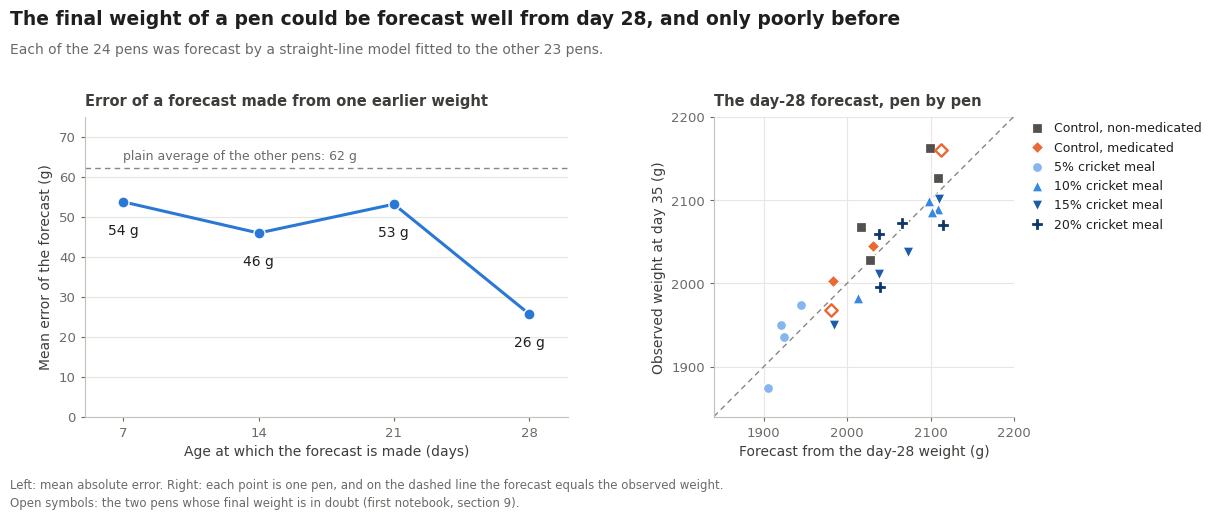

In [14]:
baseline_mae = forecast_by_age.loc["mean of the other pens (baseline)", "MAE (g)"]
mae_by_age = [forecast_by_age.loc[f"straight line on the weight at day {day}", "MAE (g)"] for day in earlier_days]
day28_forecast = forecasts["straight line on the weight at day 28"]

fig = plt.figure(figsize=(11.5, 5.0))
ax_age = fig.add_axes([0.065, 0.185, 0.42, 0.60])
ax_fit = fig.add_axes([0.60, 0.185, 0.285, 0.60])

ax_age.axhline(baseline_mae, color="#898781", linewidth=1, linestyle=(0, (4, 3)))
ax_age.text(7, baseline_mae + 1.5, f"plain average of the other pens: {baseline_mae:.0f} g", fontsize=9, color=MUTED, va="bottom")
ax_age.plot(earlier_days, mae_by_age, color=BLUE, marker="o", markersize=8, markeredgecolor="white", markeredgewidth=1, linewidth=2.2)
for day, value in zip(earlier_days, mae_by_age):
    ax_age.annotate(f"{value:.0f} g", (day, value), xytext=(0, -15), textcoords="offset points", ha="center", va="top", fontsize=10, color=INK)
ax_age.set(xlabel="Age at which the forecast is made (days)", ylabel="Mean error of the forecast (g)",
           xticks=earlier_days, xlim=(5, 30), ylim=(0, 75))
ax_age.grid(axis="x", visible=False)
ax_age.tick_params(length=3)
panel_title(ax_age, "Error of a forecast made from one earlier weight")

# Pens 18 and 20: the final weight depends on a bird number that is in doubt (first notebook, section 9.1)
final_weight_in_doubt = np.isin(pen_ids, [18, 20])

for diet in diet_order:
    of_diet = (pen_diet == diet).to_numpy()
    symbol = dict(s=marker_areas[diet], marker=diet_markers[diet], zorder=3)
    sure = of_diet & ~final_weight_in_doubt
    ax_fit.scatter(day28_forecast[sure], final_weight[sure], color=diet_colors[diet], edgecolors="white", linewidths=0.9,
                   label=diet_labels[diet], **symbol)
    doubtful = of_diet & final_weight_in_doubt
    if doubtful.any():
        ax_fit.scatter(day28_forecast[doubtful], final_weight[doubtful], facecolors="white", edgecolors=diet_colors[diet],
                       linewidths=1.7, **symbol)
perfect_line(ax_fit, 1840, 2200)
ax_fit.set(xlabel="Forecast from the day-28 weight (g)", ylabel="Observed weight at day 35 (g)")
ax_fit.set_xticks(range(1900, 2201, 100))
ax_fit.set_yticks(range(1900, 2201, 100))
ax_fit.tick_params(length=3)
ax_fit.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0), fontsize=9, handletextpad=0.3, borderaxespad=0)
panel_title(ax_fit, "The day-28 forecast, pen by pen")

headline(fig, "The final weight of a pen could be forecast well from day 28, and only poorly before",
         "Each of the 24 pens was forecast by a straight-line model fitted to the other 23 pens.")
footnote(fig, "Left: mean absolute error. Right: each point is one pen, and on the dashed line the forecast equals the observed weight.\n"
              "Open symbols: the two pens whose final weight is in doubt (first notebook, section 9).")
fig.savefig(FIGURE_DIR / "figure_9_forecast_final_weight.png")
plt.show()

Left: forecasts made at day 7, 14 or 21 stay close to the baseline, and only the day-28 forecast is clearly better. Right: the closer a pen lies to the dashed line, the better its forecast. The 5% CM pens (light blue circles), which were among the lightest at day 35, were forecast as light. The two open symbols are pens 18 and 20, whose final weight is in doubt (first notebook, section 9.1).

### Figure 10. Predicting the breast weight of a bird

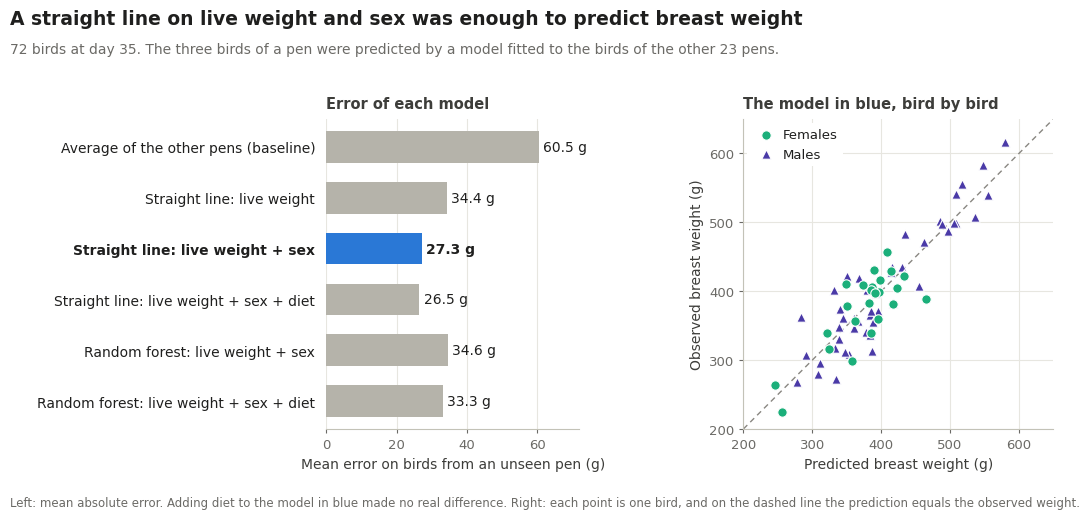

In [15]:
model_labels = {
    "mean of the other pens (baseline)": "Average of the other pens (baseline)",
    "straight line: live weight": "Straight line: live weight",
    "straight line: live weight + sex": "Straight line: live weight + sex",
    "straight line: live weight + sex + diet": "Straight line: live weight + sex + diet",
    "random forest: live weight + sex": "Random forest: live weight + sex",
    "random forest: live weight + sex + diet": "Random forest: live weight + sex + diet",
}
sex_style = {"F": ("Females", "#1baf7a", "o"), "M": ("Males", "#4a3aa7", "^")}

fig = plt.figure(figsize=(11.5, 5.0))
ax_models = fig.add_axes([0.275, 0.16, 0.22, 0.62])
ax_fit = fig.add_axes([0.63, 0.16, 0.285, 0.62])

rows = np.arange(len(model_labels))
mae = breast_results.loc[list(model_labels), "MAE (g)"].to_numpy()
ax_models.barh(rows, mae, height=0.62, color=[BLUE if name == chosen else NEUTRAL for name in model_labels])
for row, (name, value) in enumerate(zip(model_labels, mae)):
    ax_models.text(value + 1.2, row, f"{value:.1f} g", va="center", fontsize=10, color=INK, fontweight="bold" if name == chosen else "normal")
ax_models.set_yticks(rows)
ax_models.set_yticklabels(list(model_labels.values()), color=INK, fontsize=10)
for label, name in zip(ax_models.get_yticklabels(), model_labels):
    label.set_fontweight("bold" if name == chosen else "normal")
ax_models.set_ylim(len(rows) - 0.45, -0.55)
ax_models.set_xlim(0, 72)
ax_models.set_xlabel("Mean error on birds from an unseen pen (g)")
ax_models.grid(axis="y", visible=False)
ax_models.tick_params(axis="y", length=0, pad=8)
ax_models.tick_params(axis="x", length=3)
ax_models.spines["left"].set_visible(False)
panel_title(ax_models, "Error of each model")

# The 24 females are drawn on top of the 48 males, so that none of them is hidden
for layer, (sex, (label, color, marker)) in enumerate(reversed(list(sex_style.items()))):
    of_sex = (birds["sex"] == sex).to_numpy()
    ax_fit.scatter(breast_predictions[chosen][of_sex], breast_weight[of_sex], s=46, color=color, marker=marker,
                   edgecolors="white", linewidths=0.8, zorder=3 + layer, label=label)
perfect_line(ax_fit, 200, 650)
ax_fit.set(xlabel="Predicted breast weight (g)", ylabel="Observed breast weight (g)")
ax_fit.set_xticks(range(200, 601, 100))
ax_fit.set_yticks(range(200, 601, 100))
ax_fit.tick_params(length=3)
handles, labels = ax_fit.get_legend_handles_labels()
ax_fit.legend(handles[::-1], labels[::-1], loc="upper left", fontsize=9.5, handletextpad=0.3, borderaxespad=0.3,
              frameon=True, facecolor="white", edgecolor="none", framealpha=1)
panel_title(ax_fit, "The model in blue, bird by bird")

headline(fig, "A straight line on live weight and sex was enough to predict breast weight",
         "72 birds at day 35. The three birds of a pen were predicted by a model fitted to the birds of the other 23 pens.")
footnote(fig, "Left: mean absolute error. Adding diet to the model in blue made no real difference. "
              "Right: each point is one bird, and on the dashed line the prediction equals the observed weight.")
fig.savefig(FIGURE_DIR / "figure_10_breast_weight_prediction.png")
plt.show()

Left: the straight line with live weight and sex has an error of 27.3 g, less than half the error of the baseline. The random forest does about as well as the straight line on live weight alone. Right: most birds lie close to the dashed line, and the largest errors are about 80 g.

## 9. Main findings

1. **The final weight of a pen can be forecast one week ahead, and only poorly before that.** A straight line on the day-28 weight forecast the day-35 weight of an unseen pen with a mean error of 26 g (1.3%), against 62 g for the plain average. From the weight at day 7, 14 or 21 the error was 46 to 54 g.
2. **Breast weight can be predicted from live weight and sex.** The mean error was 27 g, or 7% of the breast weight, against 60.5 g for the plain average (R2 = 0.81). Every extra 100 g of live weight went with 30 g more breast, and a male had 59 g less breast than a female of the same live weight. Knowing the diet did not improve the prediction.
3. **The simplest models were the best.** A straight line beat the random forest in both tasks, and nearest neighbours in the forecasting task. Forecasts that only extended a pen's own growth (repeating the last gain, a Gompertz curve) were worse than the plain average.
4. **Data quality showed up in the models.** The weak forecast from day 21 and the two largest growth-curve errors both trace back to the two pens whose day-21 weight was flagged in the first notebook.

In short: 24 pens and 72 birds are enough for simple models that are tested honestly, and not enough for complex ones.

## 10. Limitations

- **Very little data.** 24 pens and 72 birds. The error figures are themselves uncertain, and a difference of a few grams between two models means nothing.
- **Several models, one data set.** The models were compared on the same pens that give the error figures. The error of the best model is therefore a little optimistic.
- **One trial.** One strain, one site, one period. The models describe this trial. They are not tools for another flock, feed or age.
- **Pen means.** Task A forecasts the mean weight of a pen, not the weight of a bird. Some of these means depend on bird numbers that are in doubt (first notebook, section 9).
- **Sampled birds.** The 72 birds of Task B are two males and one female from each pen. They are not a random sample of the flock.
- **Prediction is not explanation.** That diet did not improve the prediction of breast weight does not show that diet had no effect on breast meat. The second notebook looks at that question with the pen as the unit.

## 11. Reproducibility information

The notebook runs from top to bottom with no manual steps other than providing the workbook. The random forest uses random numbers. They always start from the same point (a fixed seed, `random_state=0`), so every run gives the same result, and section 7.2 shows that other seeds give almost the same error. The values of the random forest can differ slightly between scikit-learn versions.

In [16]:
print("Python      ", platform.python_version())
for module in (pd, np, matplotlib, scipy, sklearn, openpyxl):
    print(f"{module.__name__:12s}", module.__version__)

Python       3.12.3
pandas       2.2.2
numpy        2.0.2
matplotlib   3.10.0
scipy        1.16.3
sklearn      1.6.1
openpyxl     3.1.5
